# Chapter 21: Nonparametric Methods

The computational applications of this chapter of *Theory of Statistics*. The code is generated automatically from the book's `code/ch21/` files; see the book for the explanations and proofs.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/izupress/statistical-theory/blob/main/notebooks/ch_21.ipynb)

$$
\newcommand{\R}{\mathbb{R}}\newcommand{\N}{\mathbb{N}}\newcommand{\E}{\mathbb{E}}
\newcommand{\P}{\mathbb{P}}\newcommand{\F}{\mathcal{F}}\newcommand{\I}{\mathbb{I}}
\newcommand{\Var}{\operatorname{Var}}\newcommand{\Cov}{\operatorname{Cov}}
\newcommand{\Corr}{\operatorname{Corr}}\newcommand{\MSE}{\operatorname{MSE}}
\newcommand{\Bias}{\operatorname{Bias}}\newcommand{\Normal}{\mathcal{N}}
\newcommand{\iid}{\overset{\text{i.i.d.}}{\sim}}\newcommand{\pto}{\xrightarrow{P}}
\newcommand{\dto}{\xrightarrow{d}}\newcommand{\X}{\mathbf{X}}\newcommand{\x}{\mathbf{x}}
$$

In [1]:
# Setup: numpy, scipy and matplotlib are preinstalled on Colab. Locally:
#   pip install -r code/requirements.txt
# Figure files (PDF) saved by the code are written to the _figures/ folder; the figures are
# also shown inside the notebook.
import os
os.makedirs("_figures", exist_ok=True)
os.chdir("_figures")
%matplotlib inline

## Level and Power of Three Tests

With $n=30$ observations from four distributions scaled to variance $1$, we compute the rejection rates of the $t$, Wilcoxon signed-rank and sign tests under $\theta=0$ (level) and $\theta=0.5$ (power) with $M=4000$ replications.

*Source file:* `code/ch21/c21_1_t_wilcoxon_sign_power.py`

In [2]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)
n, M, alpha = 30, 4000, 0.05
dists = {                                    # all with mean 0, variance 1
    "Normal ": lambda size: rng.standard_normal(size),
    "Laplace": lambda size: rng.laplace(0, 1/np.sqrt(2), size),
    "t_3    ": lambda size: rng.standard_t(3, size) / np.sqrt(3),
    "Uniform": lambda size: rng.uniform(-np.sqrt(3), np.sqrt(3), size),
}

def rejection_rates(X):
    t = stats.ttest_1samp(X, 0, axis=1).pvalue < alpha
    w = stats.wilcoxon(X, axis=1).pvalue < alpha
    k = (X > 0).sum(axis=1)
    s = stats.binom.cdf(np.minimum(k, n - k), n, 0.5) * 2 < alpha      # two-sided sign test
    return t.mean(), w.mean(), s.mean()

print("Distrib.| theta | t-test  | Wilcoxon | sign")
for name, gen in dists.items():
    for theta in (0.0, 0.5):
        r = rejection_rates(gen((M, n)) + theta)
        print(f"{name} |  {theta:.1f}  |  {r[0]:.3f}  |  {r[1]:.3f}   | {r[2]:.3f}")

are = {"Normal ": (3/np.pi, 2/np.pi), "Laplace": (1.5, 2.0), "Uniform": (1.0, 1/3)}
print("Theoretical Pitman ARE (Wilcoxon/t, sign/t):",
      {k.strip(): (round(a, 3), round(b, 3)) for k, (a, b) in are.items()})

Distrib.| theta | t-test  | Wilcoxon | sign
Normal  |  0.0  |  0.057  |  0.057   | 0.044
Normal  |  0.5  |  0.764  |  0.745   | 0.561
Laplace |  0.0  |  0.050  |  0.057   | 0.049
Laplace |  0.5  |  0.753  |  0.837   | 0.818
t_3     |  0.0  |  0.043  |  0.053   | 0.041
t_3     |  0.5  |  0.825  |  0.935   | 0.898
Uniform |  0.0  |  0.050  |  0.046   | 0.039


Uniform |  0.5  |  0.761  |  0.689   | 0.342
Theoretical Pitman ARE (Wilcoxon/t, sign/t): {'Normal': (0.955, 0.637), 'Laplace': (1.5, 2.0), 'Uniform': (1.0, 0.333)}


## Kolmogorov–Smirnov and the Lilliefors Problem

*Source file:* `code/ch21/c21_2_kolmogorov_smirnov.py`

In [3]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)
n, M = 20, 20_000

def D(x, cdf):                                    # one-sample KS statistic sup|F_n - F|
    x = np.sort(x, axis=1); u = cdf(x); i = np.arange(1, n + 1)
    return np.maximum((i / n - u).max(axis=1), (u - (i - 1) / n).max(axis=1))

D_norm = D(rng.standard_normal((M, n)), stats.norm.cdf)
D_exp = D(rng.exponential(1.0, (M, n)), stats.expon.cdf)
q = [0.5, 0.9, 0.95, 0.99]
print("Quantiles        :", q)
print("D_n, normal data :", np.round(np.quantile(D_norm, q), 4))
print("D_n, expon. data :", np.round(np.quantile(D_exp, q), 4))
print("Exact (kstwo)    :", np.round(stats.kstwo.ppf(q, n), 4))
print("Asymptotic K/sqrt(n):", np.round(stats.kstwobign.ppf(q) / np.sqrt(n), 4))

# Lilliefors: KS critical values become invalid when parameters are estimated from the data
X = rng.normal(5, 2, (M, n))
mu, s = X.mean(axis=1, keepdims=True), X.std(axis=1, ddof=1, keepdims=True)
D_est = D((X - mu) / s, stats.norm.cdf)
crit = stats.kstwo.ppf(0.95, n)
print(f"H0 true, parameters estimated: rejection rate (target 0.05) = {(D_est > crit).mean():.4f}")
print(f"0.95 quantile of the estimated statistic = {np.quantile(D_est, 0.95):.4f} (KS critical value {crit:.4f})")

Quantiles        : [0.5, 0.9, 0.95, 0.99]
D_n, normal data : [0.1773 0.2633 0.2924 0.3512]
D_n, expon. data : [0.1775 0.264  0.2942 0.3498]
Exact (kstwo)    : [0.1773 0.2647 0.2941 0.3524]
Asymptotic K/sqrt(n): [0.1851 0.2737 0.3037 0.3639]
H0 true, parameters estimated: rejection rate (target 0.05) = 0.0000
0.95 quantile of the estimated statistic = 0.1909 (KS critical value 0.2941)


## Kernel Density Estimation: Bandwidth and Rate of Convergence

For a bimodal mixture density we plot the Gaussian-kernel estimator with different values of $h$, and measure by Monte Carlo the AMISE-optimal $h^*$ of Theorem 21.18 and the rate at which the MISE decreases with $n$.

*Source file:* `code/ch21/c21_3_kernel_density.py`

R(f'') = 1.6075
    n | h_opt  | MISE (MC) | AMISE theory


  100 | 0.2811 | 0.009296  | 0.012545


  400 | 0.2130 | 0.003604  | 0.004138


 1600 | 0.1614 | 0.001121  | 0.001365


 6400 | 0.1224 | 0.000412  | 0.000450
slope of log MISE ~ log n = -0.759 (theory: -0.8; parametric rate: -1)
n=200: Silverman h = 0.592 | AMISE-optimal h = 0.245


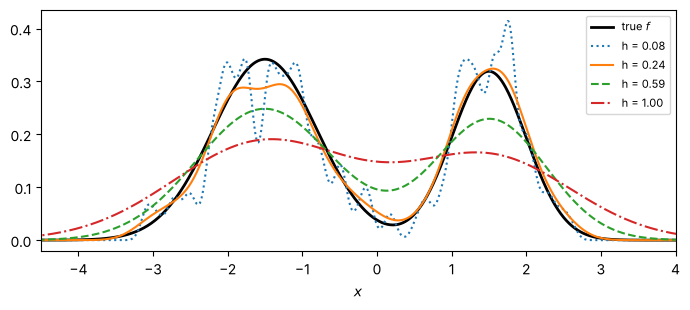

In [4]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
def f(x):                                         # bimodal mixture
    return 0.6 * stats.norm.pdf(x, -1.5, 0.7) + 0.4 * stats.norm.pdf(x, 1.5, 0.5)
def gen(n):
    k = rng.random(n) < 0.6
    return np.where(k, rng.normal(-1.5, 0.7, n), rng.normal(1.5, 0.5, n))
def kde(x, data, h):                              # Gaussian-kernel estimator
    return stats.norm.pdf((x[:, None] - data[None, :]) / h).mean(axis=1) / h

grid = np.linspace(-5, 5, 801); dx = grid[1] - grid[0]
# R(f'') numerically: AMISE-optimal h = [R(K) / (mu2^2 R(f'') n)]^(1/5); Gaussian kernel: R(K)=1/(2 sqrt(pi)), mu2=1
f2 = np.gradient(np.gradient(f(grid), dx), dx)
Rf2 = (f2**2).sum() * dx
def h_opt(n): return (1 / (2 * np.sqrt(np.pi)) / (Rf2 * n))**0.2

print(f"R(f'') = {Rf2:.4f}")
print("    n | h_opt  | MISE (MC) | AMISE theory")
res = []
for n in (100, 400, 1600, 6400):
    h = h_opt(n)
    mise = np.mean([((kde(grid, gen(n), h) - f(grid))**2).sum() * dx for _ in range(100)])
    amise = 1.25 * Rf2**0.2 * (1 / (2 * np.sqrt(np.pi)))**0.8 * n**-0.8
    res.append((n, mise)); print(f"{n:5d} | {h:.4f} | {mise:.6f}  | {amise:.6f}")
sl = np.polyfit(np.log([s[0] for s in res]), np.log([s[1] for s in res]), 1)[0]
print(f"slope of log MISE ~ log n = {sl:.3f} (theory: -0.8; parametric rate: -1)")

data = gen(200)
h_silv = 1.06 * data.std(ddof=1) * 200**-0.2
print(f"n=200: Silverman h = {h_silv:.3f} | AMISE-optimal h = {h_opt(200):.3f}")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(grid, f(grid), "k", lw=2, label="true $f$")
for h, st in ((0.08, ":"), (h_opt(200), "-"), (h_silv, "--"), (1.0, "-.")):
    ax.plot(grid, kde(grid, data, h), st, label=f"h = {h:.2f}")
ax.set_xlim(-4.5, 4); ax.legend(fontsize=8); ax.set_xlabel("$x$")
fig.tight_layout(); fig.savefig("cekirdek_bant.pdf")

## U-Statistics: Exact Variance and Asymptotic Normality

The first part compares, for standard normal data, $n\Var(U_n)$ of Gini's mean difference ($h=|x_1-x_2|$, $\theta=2/\sqrt\pi$) with the exact formula of Theorem 21.14 and with the limit $m^2\zeta_1=4\zeta_1$. Since $h_1(x)=\E|x-X|=2\varphi(x)+x\big(2\Phi(x)-1\big)$, $\zeta_1$ is found by numerical integration; $\zeta_2=\Var|X_1-X_2|=2-4/\pi$. The second part studies the Walsh-pair U-statistic (Corollary 21.16) on $\Normal(0.3,\,1)$ data: away from the null hypothesis the asymptotic variance is not $1/3$ but $4\zeta_1$. The last column is the miss rate of the $95%$ interval built with the normal approximation.

*Source file:* `code/ch21/c21_5_u_statistics.py`

In [5]:
import numpy as np
from scipy import stats, integrate

rng = np.random.default_rng(42)
phi, Phi = stats.norm.pdf, stats.norm.cdf

# 1) Gini's mean difference: h(x1, x2) = |x1 - x2|, data N(0, 1)
theta = 2 / np.sqrt(np.pi)
h1 = lambda x: 2 * phi(x) + x * (2 * Phi(x) - 1)           # h_1(x) = E|x - X|
zeta1 = integrate.quad(lambda x: (h1(x) - theta)**2 * phi(x), -np.inf, np.inf)[0]
zeta2 = 2 - 4 / np.pi                                      # Var|X1 - X2|
print(f"Gini: theta = {theta:.4f} | zeta_1 = {zeta1:.4f}, zeta_2 = {zeta2:.4f} | m^2 zeta_1 = {4*zeta1:.4f}")
R = 20_000
for n in [5, 20, 100]:
    X = np.sort(rng.normal(size=(R, n)), axis=1)
    i = np.arange(1, n + 1)
    U = 2 * np.sum((2 * i - n - 1) * X, axis=1) / (n * (n - 1))  # O(n) computation from sorted data
    exact = 2 / (n * (n - 1)) * (2 * (n - 2) * zeta1 + zeta2)
    print(f"  n={n:3d} | mean(U) = {U.mean():.4f} | n*Var(U) = {n*U.var():.4f}"
          f" | exact n*Var = {n*exact:.4f} | skewness = {stats.skew(U):+.3f}")

# 2) Walsh pairs: h(x1, x2) = I{x1 + x2 > 0}, data N(0.3, 1) (the Wilcoxon U-statistic)
d = 0.3
p = Phi(2 * d / np.sqrt(2))                                # P(X1 + X2 > 0)
zeta1 = integrate.quad(lambda x: (Phi(x + d) - p)**2 * phi(x - d), -np.inf, np.inf)[0]
print(f"Walsh: p = {p:.4f} | 4 zeta_1 = {4*zeta1:.4f} (1/3 = 0.3333 under H0)")
for n in [10, 50]:
    X = rng.normal(d, 1, size=(R, n))
    iu = np.triu_indices(n, 1)
    U = ((X[:, iu[0]] + X[:, iu[1]]) > 0).mean(axis=1)
    exact = 2 / (n * (n - 1)) * (2 * (n - 2) * zeta1 + p * (1 - p))   # zeta_2 = Var h = p(1 - p)
    z = np.sqrt(n) * (U - p) / np.sqrt(4 * zeta1)
    print(f"  n={n:3d} | mean(U) = {U.mean():.4f} | n*Var(U) = {n*U.var():.4f} | exact n*Var = {n*exact:.4f}"
          f" | P(|z| > 1.96) = {np.mean(np.abs(z) > 1.96):.4f}")

Gini: theta = 1.1284 | zeta_1 = 0.1628, zeta_2 = 0.7268 | m^2 zeta_1 = 0.6510
  n=  5 | mean(U) = 1.1309 | n*Var(U) = 0.8675 | exact n*Var = 0.8516 | skewness = +0.457
  n= 20 | mean(U) = 1.1286 | n*Var(U) = 0.7001 | exact n*Var = 0.6932 | skewness = +0.191
  n=100 | mean(U) = 1.1281 | n*Var(U) = 0.6495 | exact n*Var = 0.6591 | skewness = +0.086
Walsh: p = 0.6643 | 4 zeta_1 = 0.2883 (1/3 = 0.3333 under H0)
  n= 10 | mean(U) = 0.6662 | n*Var(U) = 0.3058 | exact n*Var = 0.3058 | P(|z| > 1.96) = 0.0518


  n= 50 | mean(U) = 0.6652 | n*Var(U) = 0.2910 | exact n*Var = 0.2915 | P(|z| > 1.96) = 0.0507


## Real Data: Student's Sleep Data

The data in which Cushny and Peebles measured the effect of two sleeping drugs on 10 patients  are the example Student used in the paper that introduced the $t$ distribution . Every patient took both drugs; the measurement is the extra sleep produced by the drug (hours). Since patients differ a lot, the analysis must use the differences $d_i=\text{drug}_2-\text{drug}_1$. The data have two small features: one difference is zero and two differences are equal. So in the sign and Wilcoxon tests the zero difference is dropped, the equal differences get midranks, and the null distribution is computed exactly (conditionally) by enumerating the $2^9$ sign assignments. The code compares the paired $t$ test (Chapter 16), the sign test, the Wilcoxon signed-rank test and the sign-flip permutation test; it then shows the wrong analysis that ignores the pairing.

*Source file:* `code/ch21/c21_4_sleep_data_real_data.py`

In [6]:
import itertools
import numpy as np
from scipy import stats

# Cushny and Peebles (1905), Student (1908): extra sleep (hours) produced by two drugs in the same 10 patients.
# Source: R, datasets::sleep.
drug1 = np.array([
    0.7, -1.6, -0.2, -1.2, -0.1, 3.4, 3.7, 0.8, 0.0, 2.0,
])
drug2 = np.array([
    1.9, 0.8, 1.1, 0.1, -0.1, 4.4, 5.5, 1.6, 4.6, 3.4,
])
d = np.round(drug2 - drug1, 1)
n = len(d)
print(f"differences d = {d} | mean = {d.mean():.2f}, s = {d.std(ddof=1):.3f}, median = {np.median(d):.2f}")

# 1) Paired t test and 95% confidence interval (Chapter 16)
t = d.mean() / (d.std(ddof=1) / np.sqrt(n))
q = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n)
print(f"paired t: t = {t:.3f}, p = {2 * stats.t.sf(abs(t), n - 1):.4f}, 95% CI = [{d.mean() - q:.2f}, {d.mean() + q:.2f}]")

# 2) Sign test (the zero difference is dropped)
s = d[d != 0]
k = int(np.sum(s > 0))
print(f"sign test: {k}/{len(s)} positive, p = {stats.binomtest(k, len(s)).pvalue:.4f}")

# 3) Wilcoxon signed-rank test: midranks for ties; exact conditional distribution by enumeration
r = stats.rankdata(np.abs(s))
W = r[s > 0].sum()
signs = np.array(list(itertools.product([0, 1], repeat=len(s))))
W_null = signs @ r
p_w = np.mean(np.abs(W_null - r.sum() / 2) >= abs(W - r.sum() / 2) - 1e-9)
print(f"Wilcoxon: W+ = {W:.1f} (largest possible value {r.sum():.0f}), exact p = {p_w:.4f}")

# 4) Permutation (sign-flip) test: under H0 each difference is equally likely to have either sign
S = np.array(list(itertools.product([-1, 1], repeat=n)))
means = (S * d).mean(axis=1)
print(f"permutation: 2^{n} = {len(means)} sign assignments, p = {np.mean(np.abs(means) >= abs(d.mean()) - 1e-12):.4f}")

# 5) Wrong analysis: a two-sample t test that ignores the pairing
two = stats.ttest_ind(drug2, drug1)
print(f"two-sample t (wrong): t = {two.statistic:.3f}, p = {two.pvalue:.4f} | Corr(drug1, drug2) = {np.corrcoef(drug1, drug2)[0, 1]:.3f}")

differences d = [1.2 2.4 1.3 1.3 0.  1.  1.8 0.8 4.6 1.4] | mean = 1.58, s = 1.230, median = 1.30
paired t: t = 4.062, p = 0.0028, 95% CI = [0.70, 2.46]
sign test: 9/9 positive, p = 0.0039
Wilcoxon: W+ = 45.0 (largest possible value 45), exact p = 0.0039
permutation: 2^10 = 1024 sign assignments, p = 0.0039
two-sample t (wrong): t = 1.861, p = 0.0792 | Corr(drug1, drug2) = 0.795
